# Les 7 datasets du concours en une seule visualisation
**Objectif** : une figure unique pour comparer les 7 instances, avant de chercher la moindre solution.

**Prérequis** : seulement `datasets/*.json` et `pandas` + `matplotlib`. Le notebook n'utilise aucun autre fichier du projet. Les instances absentes sont ignorées.

**Plan** : (1) charger chaque JSON en deux DataFrames, `models` et `datasets` ; (2) calculer un petit tableau de chiffres par instance ; (3) tracer la figure ; (4) la lire.

## 1. Charger les instances

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NAMES = ["1_example", "2_medium", "3_free", "4_precise", "5_energy", "6_shortage", "7_big"]
TYPES = ["n", "t", "i", "c"]

def load_instance(path):
    """Un fichier JSON -> (energy_cap, models, requirements, datasets)."""
    with open(path) as f:
        instance = json.load(f)
    energy_cap = instance["energyCap"]                      # le plafond d'énergie, isolé dans une variable
    models = pd.DataFrame(instance["models"])[["id", "value", "energyCost"]].rename(
        columns={"id": "model_id", "energyCost": "energy_cost"})
    requirements = pd.DataFrame(                             # une ligne par besoin (modèle, type de données)
        [(m["id"], t, b["lowerBound"], b["upperBound"])
         for m in instance["models"] for t, b in m["dataRequirements"].items()],
        columns=["model_id", "data_type", "lower", "upper"])
    datasets = pd.DataFrame(instance["datasets"]).rename(
        columns={"id": "dataset_id", "dataType": "data_type", "isCopyrighted": "is_copyrighted"})
    return energy_cap, models, requirements, datasets

INSTANCES = {}
for name in NAMES:
    path = ROOT_DIR / "datasets" / f"{name}.json"
    if path.exists():
        INSTANCES[name] = load_instance(path)
print("chargées :", list(INSTANCES))
print("absentes :", [n for n in NAMES if n not in INSTANCES])

chargées : ['1_example', '2_medium', '3_free', '4_precise', '5_energy', '6_shortage', '7_big']
absentes : []


## 2. Les chiffres à comparer
Une ligne par instance. Ce tableau est aussi la **version texte de la figure** : chaque barre ou point de la figure s'y retrouve.

Deux particularités des données : (1) environ 5 à 6 % des modèles ont une énergie quasi nulle (`energy_cost` ≈ 1) ; on les compte à part (`modèles_énergie_nulle`) et on les exclut de la case « poids d'un modèle », sinon ils écrasent l'échelle. (2) Certains besoins ont `upper < lower` (par exemple `lower = 1`, `upper = -537`). Aucun dataset ne peut les remplir ; seul un modèle source peut les couvrir. On les compte à part (`modèles_impossibles`) et on les exclut des calculs de largeur.

In [2]:
rows, per_type, energy_ratio = [], [], {}
for name, (cap, models, req, data) in INSTANCES.items():
    req = req.assign(impossible=req.upper < req.lower)
    valid = req[~req.impossible]
    n_req = req.groupby("model_id").size()
    mono = n_req.eq(1)
    energy_ratio[name] = models.energy_cost / cap            # énergie d'un modèle, en part du plafond
    free_energy = models.energy_cost <= 10                   # ~5-6 % des modèles coûtent ≈ 1 : énergie quasi nulle

    for t in TYPES:
        supply = data.loc[data.data_type == t, "size"].sum()
        demand = valid.loc[valid.data_type == t, "lower"].sum()
        n_t = (data.data_type == t).sum()
        if n_t:                                               # le type existe dans cette instance
            per_type.append(dict(instance=name, data_type=t, demande_sur_offre=demand / supply,
                                 part_libre=(data.loc[data.data_type == t, "is_copyrighted"] == 0).mean()))

    rows.append(dict(
        instance=name, modèles=len(models), datasets=len(data),
        énergie_totale_sur_plafond=models.energy_cost.sum() / cap,
        demande_sur_offre=valid.lower.sum() / data["size"].sum(),
        part_libre=(data.is_copyrighted == 0).mean(),
        besoins_par_modèle_moy=n_req.mean(),
        largeur_bornes_médiane=((valid.upper - valid.lower) / valid.lower.clip(lower=1)).median(),
        modèles_un_seul_besoin=mono.mean(),
        modèles_impossibles=req.groupby("model_id").impossible.max().mean(),
        modèles_énergie_nulle=free_energy.mean()))

summary = pd.DataFrame(rows).set_index("instance")
per_type = pd.DataFrame(per_type)
n_req_share = pd.DataFrame({name: INSTANCES[name][2].groupby("model_id").size().value_counts(normalize=True)
                            for name in INSTANCES}).T.reindex(columns=[1, 2, 3, 4]).fillna(0)
summary.round(3)

,modèles,datasets,énergie_totale_sur_plafond,demande_sur_offre,part_libre,besoins_par_modèle_moy,largeur_bornes_médiane,modèles_un_seul_besoin,modèles_impossibles,modèles_énergie_nulle
instance,,,,,,,,,,
1_example,5,5,1.629,1.809,0.400,1.200,0.215,0.800,0.000,0.000
2_medium,3000,10000,7.282,2.892,0.343,2.017,0.163,0.420,0.019,0.052
3_free,5000,20000,7.955,2.368,1.000,1.980,0.161,0.434,0.019,0.059
4_precise,8000,40000,5.956,2.003,0.499,2.799,0.000,0.000,0.048,0.061
5_energy,11000,100000,0.920,1.044,0.341,2.000,0.161,0.422,0.021,0.060
6_shortage,15000,5000,7.573,28.186,0.592,2.020,0.142,0.401,0.018,0.061
7_big,50000,250000,5.823,1.886,0.340,1.994,0.164,0.429,0.021,0.061


## 3. Les graphiques
Huit questions, une par case, les mêmes instances dans le même ordre sur chaque axe horizontal.

**Couleurs** : la couleur n'est utilisée que pour le **type de données** (bleu `n`, orange `t`, vert `i`, jaune `c`), dans les deux cases où il compte. Partout ailleurs, le gris : ainsi une couleur a toujours le même sens dans toute la figure.

In [3]:
# Palette (jetons) : un jeton = un rôle
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e1", "#fcfcfb"
TYPE_COLOR = {"n": "#2a78d6", "t": "#eb6834", "i": "#1baf7a", "c": "#eda100"}
GRAY_DARK, GRAY_LIGHT = "#6b6a66", "#c9c8c3"
GRAY_RAMP = ["#dddcd7", "#b5b4ae", "#85847e", "#52514e"]        # 1 -> 4 besoins : clair -> foncé

plt.rcParams.update({"axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 9})

names = list(INSTANCES)
x = np.arange(len(names))
w, w3 = 0.38, 0.26

def style(ax, title, subtitle=None, big=False):
    """Titre, sous-titre et graduations horizontales (une instance par position)."""
    ax.set_title(title, loc="left", fontsize=14 if big else 10.5, fontweight="bold", color=INK, pad=22 if big else (14 if subtitle else 6))
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=10 if big else 8, color=INK_2, va="bottom")
    ax.set_xticks(x)
    ax.set_xticklabels(names if big else [n.replace("_", "\n") for n in names], fontsize=10 if big else 8)
    ax.grid(axis="x", visible=False)

def type_dots(ax, column, big=False):
    """Un point par (instance, type de données), décalé horizontalement pour ne pas se recouvrir."""
    for k, t in enumerate(TYPES):
        d = per_type[per_type.data_type == t].set_index("instance").reindex(names)
        ax.scatter(x + (k - 1.5) * 0.15, d[column], s=110 if big else 46, color=TYPE_COLOR[t],
                   edgecolor=SURFACE, linewidth=1.2, label=t, zorder=3)

def legend_below(ax, big=False, **kw):
    ax.legend(frameon=False, fontsize=10 if big else 8, loc="upper center",
              bbox_to_anchor=(0.5, -0.12 if big else -0.17), columnspacing=1.2, handletextpad=0.3, **kw)

def label_bars(ax, xs, values, fmt, big):
    """Étiquettes de valeur au-dessus des barres (uniquement sur les grandes figures)."""
    if big:
        for xi, v in zip(xs, values):
            if v < 0.005:                                    # valeurs nulles : pas d'étiquette (le « ≈ 0 » est écrit à part)
                continue
            ax.annotate(fmt(v), (xi, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK)

# --- une fonction par case : chacune dessine sur un axe `ax` ---
def panel_taille(ax, big=False):
    ax.bar(x - w / 2, summary.modèles, w, color=GRAY_DARK, label="modèles")
    ax.bar(x + w / 2, summary.datasets, w, color=GRAY_LIGHT, label="datasets")
    label_bars(ax, x - w / 2, summary.modèles, lambda v: f"{int(v):,}".replace(",", " "), big)
    label_bars(ax, x + w / 2, summary.datasets, lambda v: f"{int(v):,}".replace(",", " "), big)
    ax.set_yscale("log"); style(ax, "Taille", "nombre de modèles et de datasets, échelle log", big)
    ax.legend(frameon=False, fontsize=10 if big else 8, loc="upper left")

def panel_energie(ax, big=False):
    ax.bar(x, summary.énergie_totale_sur_plafond, 0.6, color=GRAY_DARK)
    label_bars(ax, x, summary.énergie_totale_sur_plafond, lambda v: f"{v:.2f}", big)
    ax.axhline(1, color=INK, lw=1.2)
    ax.text(-0.45, 1.12, "plafond", ha="left", fontsize=10 if big else 8, color=INK,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5), zorder=5)
    style(ax, "Énergie : tout entrer ?", "énergie de tous les modèles ÷ plafond d'énergie", big)

def panel_donnees(ax, big=False):
    type_dots(ax, "demande_sur_offre", big); ax.axhline(1, color=INK, lw=1.2); ax.set_yscale("log")
    ax.text(-0.5, 1.07, "offre = demande", ha="left", va="bottom", fontsize=10 if big else 8, color=INK)
    style(ax, "Données : assez pour tous ?", "somme des `lower` ÷ offre, par type de données, échelle log", big)
    legend_below(ax, big, ncol=4)

def panel_droits(ax, big=False):
    type_dots(ax, "part_libre", big); ax.set_ylim(-0.03, 1.03)
    style(ax, "Droits d'auteur", "part de datasets libres de droits, par type de données", big)
    legend_below(ax, big, ncol=4)

def panel_structure(ax, big=False):
    bottom = np.zeros(len(names))
    for k, c in enumerate([1, 2, 3, 4]):
        ax.bar(x, n_req_share[c], 0.6, bottom=bottom, color=GRAY_RAMP[k], edgecolor=SURFACE, linewidth=1.5,
               label=f"{c} besoin" + ("s" if c > 1 else ""))
        if big:                                              # pourcentage dans chaque segment assez haut
            for xi, b, v in zip(x, bottom, n_req_share[c]):
                if v > 0.06:
                    ax.text(xi, b + v / 2, f"{v:.0%}", ha="center", va="center", fontsize=9, color=INK if k < 2 else SURFACE)
        bottom += n_req_share[c].values
    ax.set_ylim(0, 1); style(ax, "Structure des modèles", "répartition du nombre de besoins par modèle", big)
    legend_below(ax, big, ncol=4)

def panel_poids(ax, big=False):
    bp = ax.boxplot([energy_ratio[n][INSTANCES[n][1].energy_cost > 10] for n in names], positions=x, widths=0.5,
                    whis=(5, 95), showfliers=False, patch_artist=True, medianprops=dict(color=INK, lw=1.6),
                    whiskerprops=dict(color=GRAY_DARK), capprops=dict(color=GRAY_DARK))
    for patch in bp["boxes"]:
        patch.set(facecolor=GRAY_LIGHT, edgecolor=GRAY_DARK)
    ax.set_yscale("log")
    style(ax, "Poids d'un modèle", "énergie d'un modèle ÷ plafond, échelle log (5-95 %), sans les modèles à énergie ≈ 0", big)

def panel_precision(ax, big=False):
    ax.bar(x, summary.largeur_bornes_médiane, 0.6, color=GRAY_DARK)
    label_bars(ax, x, summary.largeur_bornes_médiane, lambda v: f"{v:.3f}", big)
    for xi, v in zip(x, summary.largeur_bornes_médiane):
        if v < 0.005:
            ax.text(xi, 0.004, "≈ 0", ha="center", va="bottom", fontsize=10 if big else 8, color=INK)
    style(ax, "Précision des besoins", "(upper − lower) ÷ lower, médiane : plus c'est petit, plus le besoin est précis", big)

def panel_particuliers(ax, big=False):
    series = [(-w3, summary.modèles_un_seul_besoin, GRAY_DARK, "un seul besoin (source possible)"),
              (0, summary.modèles_impossibles, GRAY_RAMP[1], "besoin impossible (source obligatoire)"),
              (w3, summary.modèles_énergie_nulle, GRAY_RAMP[0], "énergie ≈ 0")]
    for dx, values, color, label in series:
        ax.bar(x + dx, values, w3, color=color, label=label, edgecolor=GRAY_DARK if color == GRAY_RAMP[0] else "none", linewidth=0.8)
        label_bars(ax, x + dx, values, lambda v: f"{v:.0%}", big)
    ax.set_ylim(0, 1); style(ax, "Modèles particuliers", "part des modèles de l'instance", big)
    ax.legend(frameon=False, fontsize=10 if big else 7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12 if big else -0.17))

PANELS = [panel_taille, panel_energie, panel_donnees, panel_droits,
          panel_structure, panel_poids, panel_precision, panel_particuliers]

## 4. Vue d'ensemble : les 8 cases côte à côte
C'est la vue pour comparer d'un coup d'œil. Les parties suivantes reprennent chaque case en grand.

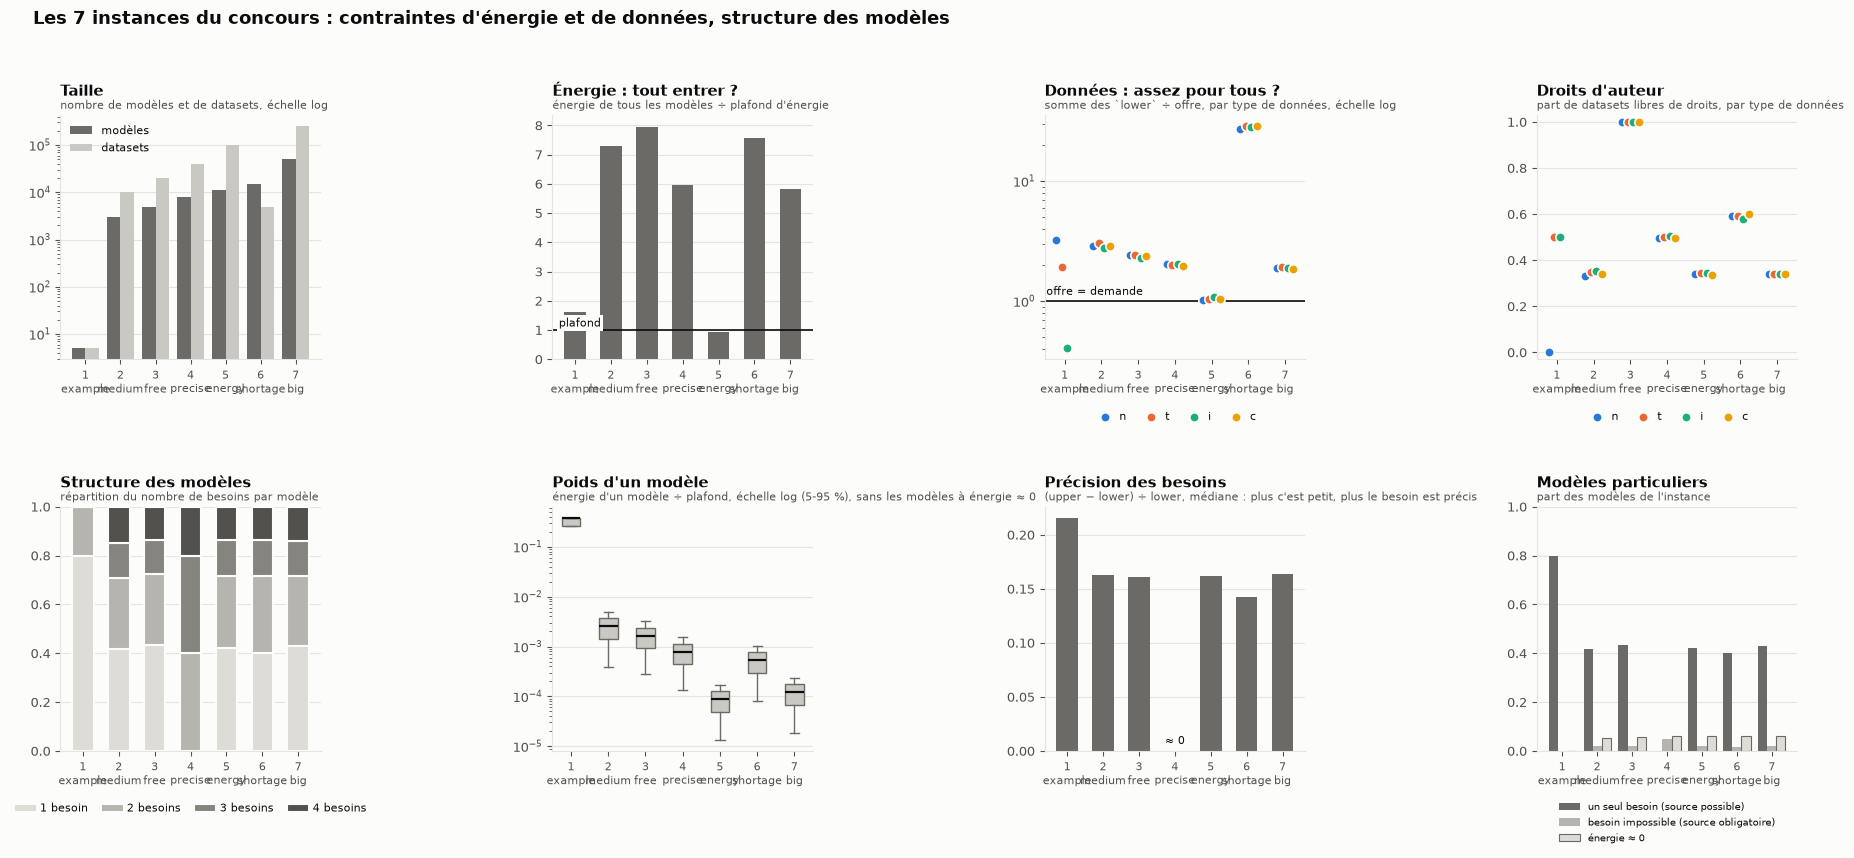

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8.8))
for panel, ax in zip(PANELS, axes.ravel()):
    panel(ax)
fig.suptitle("Les 7 instances du concours : contraintes d'énergie et de données, structure des modèles", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=3)
plt.show()

## 5. Chaque case en grand
Les mêmes graphiques, plus grands, avec les valeurs écrites quand c'est utile.

### A. Taille
Combien de modèles et de datasets ? L'échelle est logarithmique : chaque graduation vaut dix fois la précédente.

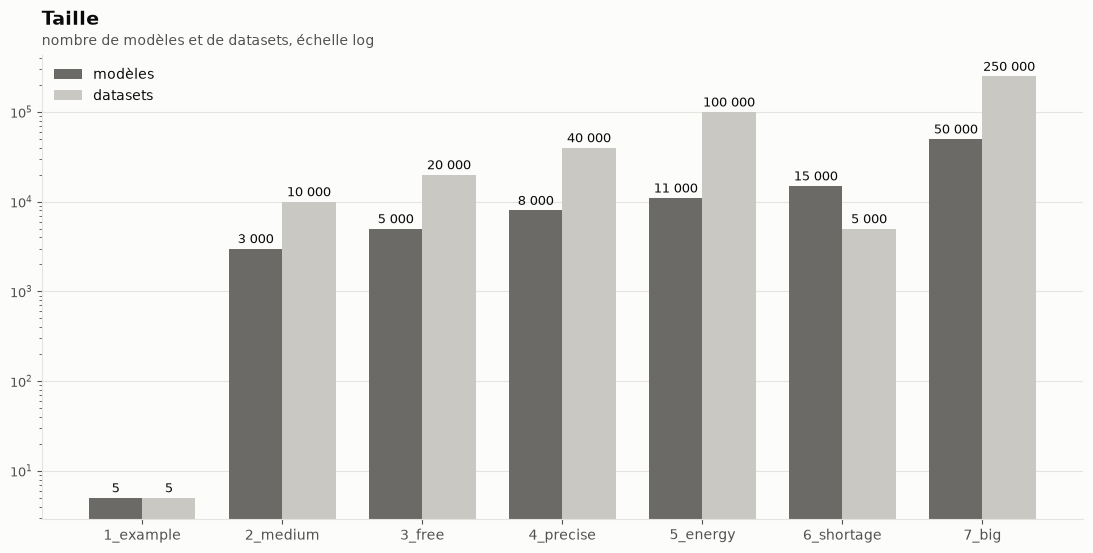

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_taille(ax, big=True)
fig.tight_layout()
plt.show()

### B. Énergie : tout entrer ?
Au-dessus de la ligne, l'énergie de tous les modèles dépasse le plafond : il faut choisir. Plus la barre est haute, plus le choix est sélectif.

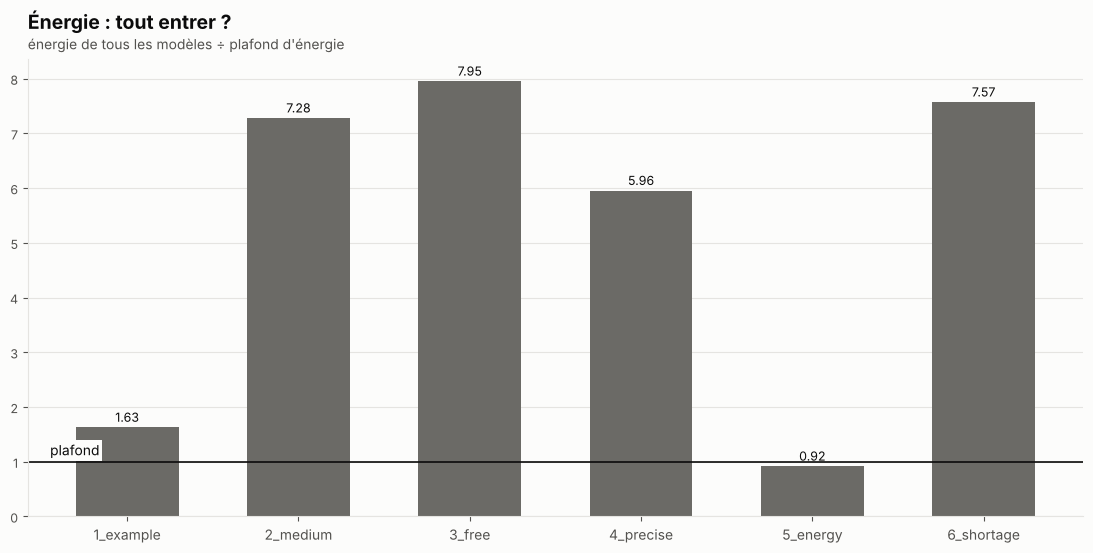

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_energie(ax, big=True)
fig.tight_layout()
plt.show()

### C. Données : assez pour tous ?
Rapport entre la somme des besoins minimaux et l'offre, pour chaque type. Au-dessus de 1, les modèles ne peuvent pas tous être servis.

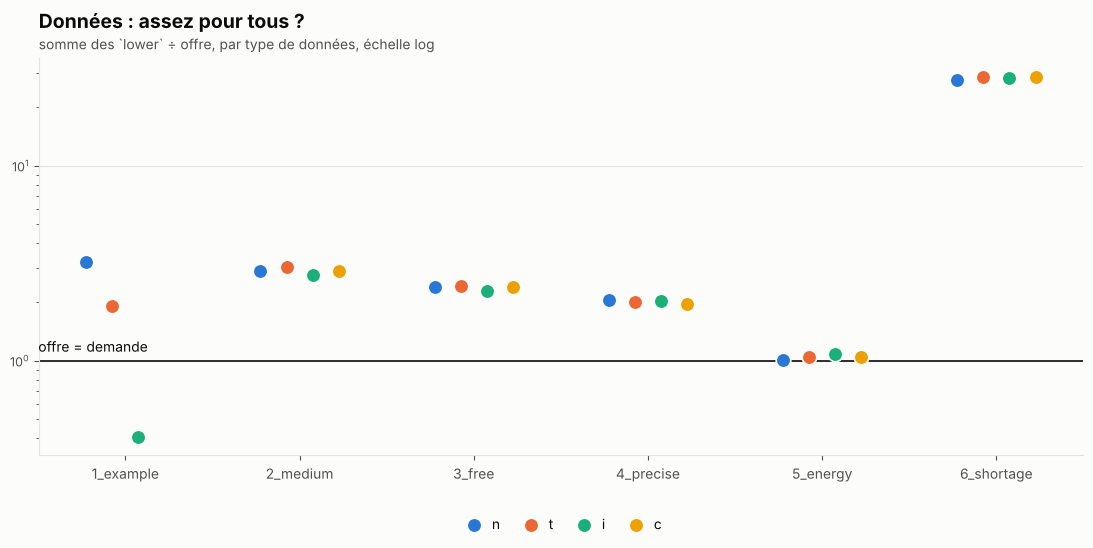

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_donnees(ax, big=True)
fig.tight_layout()
plt.show()

### D. Droits d'auteur
Un dataset sous droits d'auteur divise par deux la valeur du modèle qui l'utilise. Ici, la part de datasets libres, par type.

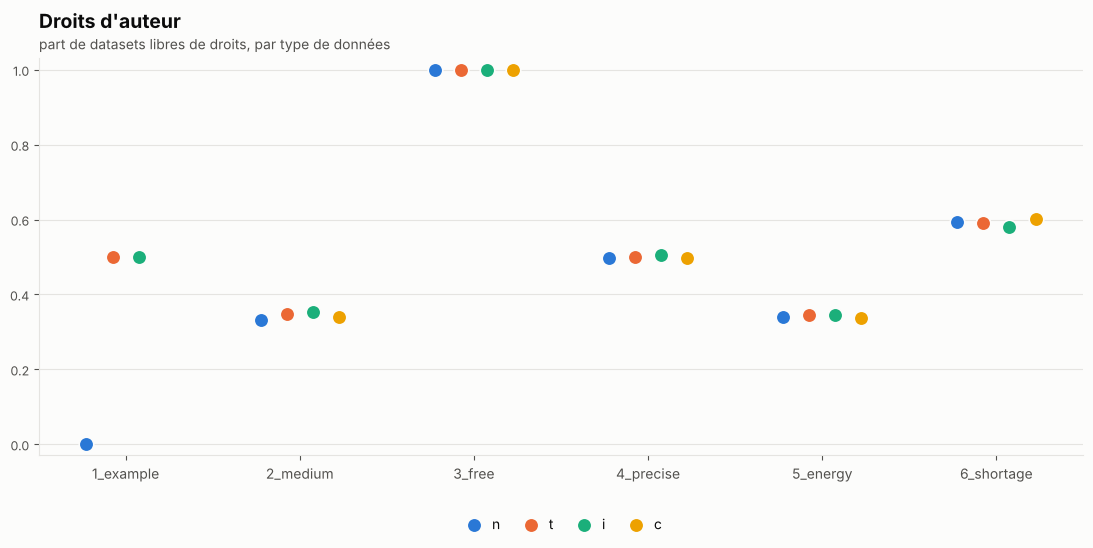

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_droits(ax, big=True)
fig.tight_layout()
plt.show()

### E. Structure des modèles
Un modèle à un seul besoin peut servir de source ; plus un modèle a de besoins, plus il est difficile à satisfaire.

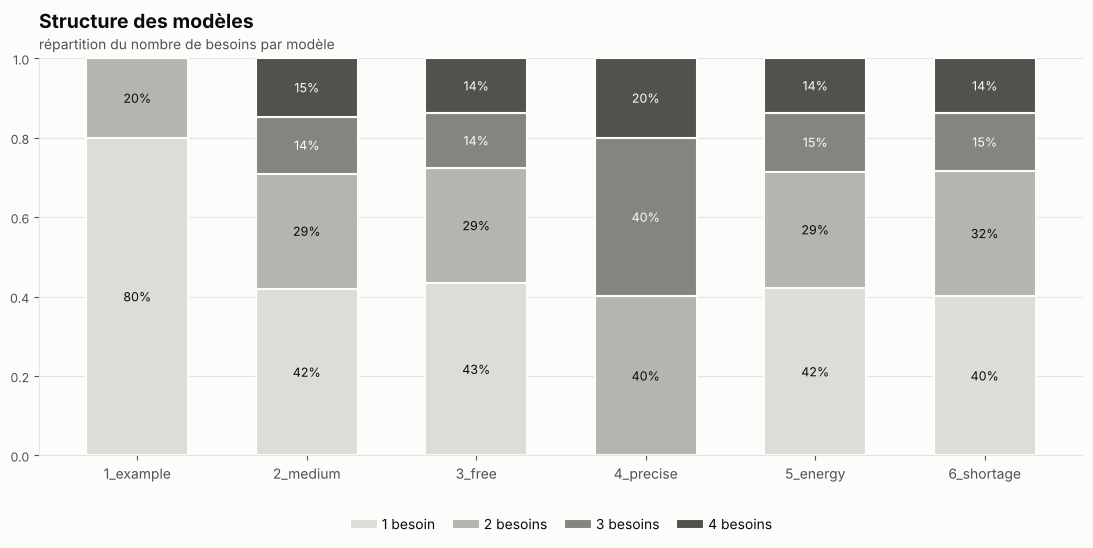

In [9]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_structure(ax, big=True)
fig.tight_layout()
plt.show()

### F. Poids d'un modèle
Énergie d'un modèle rapportée au plafond : plus la boîte est basse, plus on peut en entraîner.

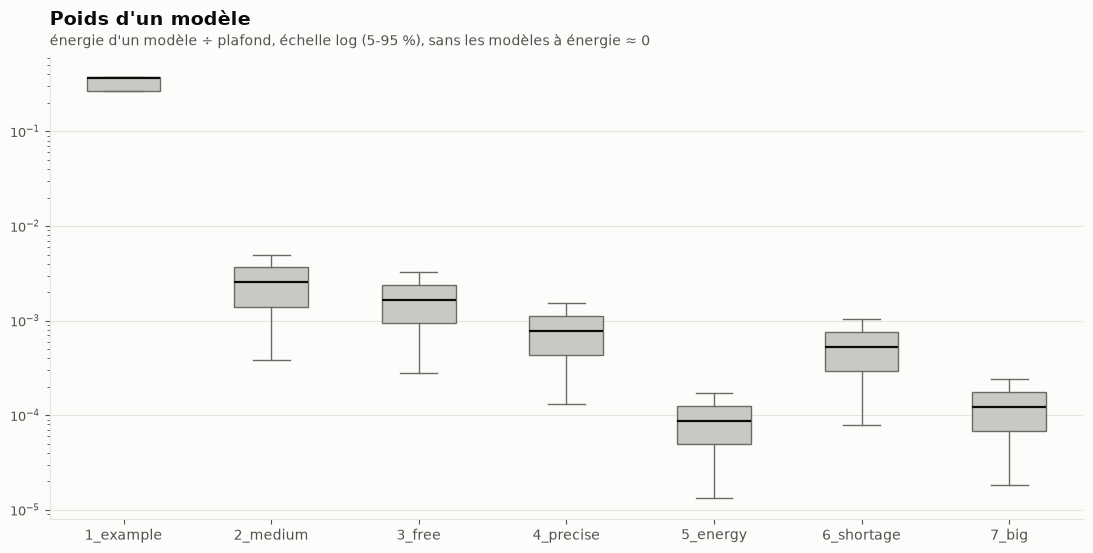

In [7]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_poids(ax, big=True)
fig.tight_layout()
plt.show()

### G. Précision des besoins
Largeur de l'intervalle `[lower, upper]` rapportée à `lower` : à zéro, il faut atteindre la taille exacte.

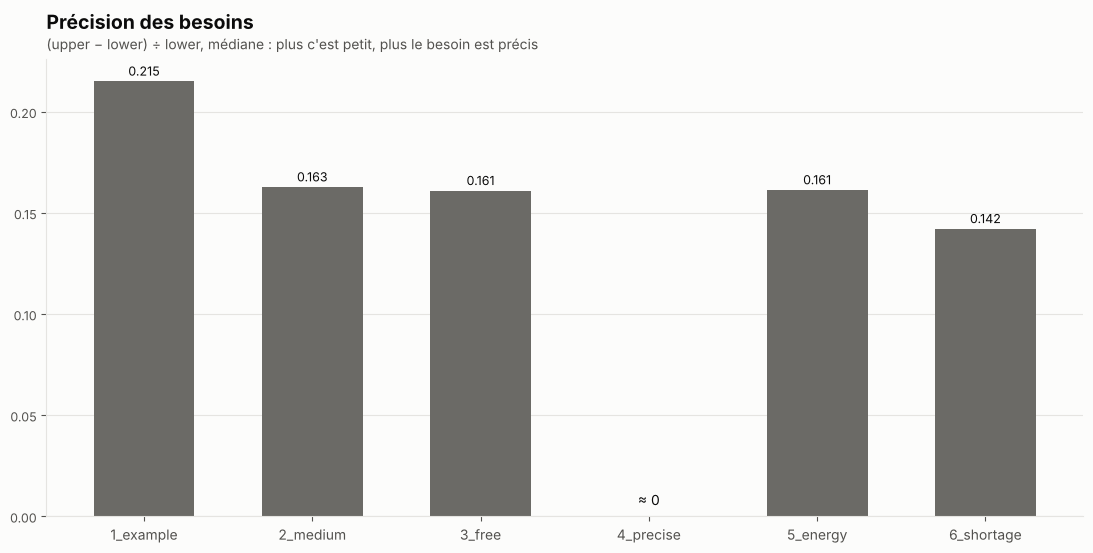

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_precision(ax, big=True)
fig.tight_layout()
plt.show()

### H. Modèles particuliers
Les modèles à un seul besoin (sources possibles), ceux dont un besoin est impossible à remplir avec des datasets, et ceux à énergie quasi nulle.

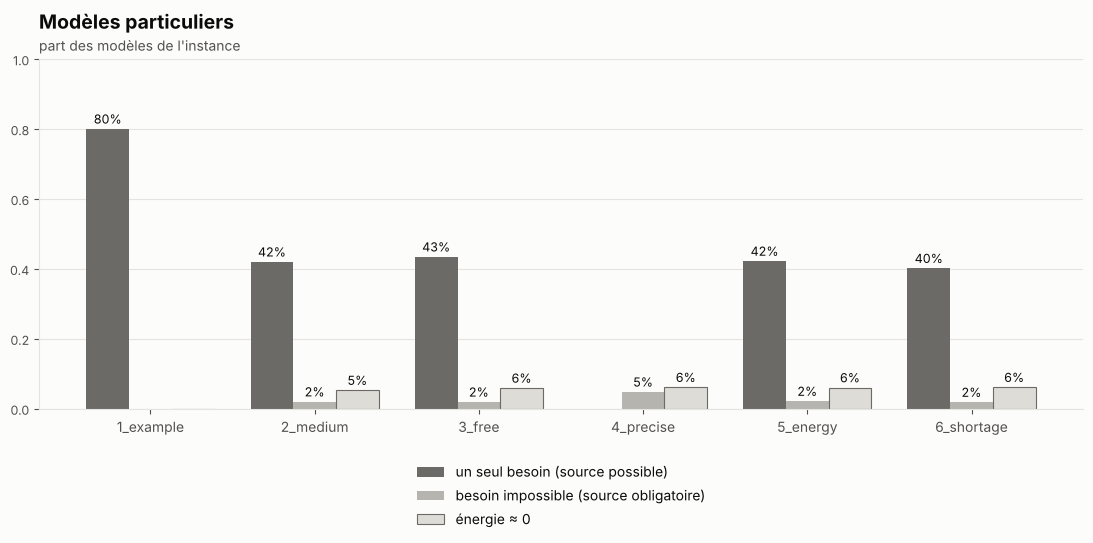

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.6))
panel_particuliers(ax, big=True)
fig.tight_layout()
plt.show()

## 6. Comment lire la figure
Les cases se lisent dans cet ordre : **taille** (A), puis les deux contraintes **énergie** (B) et **données** (C, D), puis la **forme des modèles** (E, F, G), enfin les **modèles particuliers** (H). Le tableau de la partie 2 donne les valeurs exactes.